# Breast Cancer Wisconsin (Original)：二分类任务

数据来源：UCI Machine Learning Repository。设计目标是根据细胞核特征辅助筛查恶性肿瘤，恶性为正类，因此重点关注 recall。

题目中的 cross_val_points() 按课程常见写法理解为 cross_val_score()。本 Notebook 使用 cross_val_score() 和 cross_val_predict()。


## 1. 获取数据、说明数据集和设计目标

**这一步在做什么：** 1. 获取数据、说明数据集和设计目标。  
**为什么要做：** 读取 UCI 官方原始数据，明确字段、标签与缺失值；筛查任务中漏掉恶性病例的代价通常高于误报。  
**如何纳入 Pipeline：** 本步只读取原始 DataFrame，后续预处理在 Pipeline 中完成。


In [1]:
from pathlib import Path
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/breast-cancer-wisconsin.data"
DATA_PATH = Path("breast-cancer-wisconsin.data")
if not DATA_PATH.is_file():
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)
columns = ["id", "clump_thickness", "cell_size_uniformity", "cell_shape_uniformity", "marginal_adhesion", "single_epithelial_cell_size", "bare_nuclei", "bland_chromatin", "normal_nucleoli", "mitoses", "class"]
data = pd.read_csv(DATA_PATH, header=None, names=columns).replace("?", np.nan)
print("样本数和字段数：", data.shape)
display(data.head())


样本数和字段数： (699, 11)


,id,clump_thickness,cell_size_uniformity,cell_shape_uniformity,marginal_adhesion,single_epithelial_cell_size,bare_nuclei,bland_chromatin,normal_nucleoli,mitoses,class
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2


## 2. 数据探索与标签编码

**这一步在做什么：** 2. 数据探索与标签编码。  
**为什么要做：** 检查缺失值和类别分布；原始标签 2/4 需要映射为 0/1，问号需要作为缺失值处理。  
**如何纳入 Pipeline：** 缺失值由后续 SimpleImputer 在每个训练折中学习。


In [2]:
print("缺失值统计：")
display(data.isna().sum().to_frame("missing_count"))
print("原始类别分布：")
display(data["class"].value_counts().sort_index())
features = [c for c in columns if c not in ["id", "class"]]
X = data[features].apply(pd.to_numeric)
y = data["class"].map({2: 0, 4: 1}).astype(int)
print("0=良性，1=恶性；恶性比例：", f"{y.mean():.1%}")
display(X.describe().T)


缺失值统计：


,missing_count
id,0
clump_thickness,0
cell_size_uniformity,0
cell_shape_uniformity,0
marginal_adhesion,0
single_epithelial_cell_size,0
bare_nuclei,16
bland_chromatin,0
normal_nucleoli,0
mitoses,0


原始类别分布：


class
2    458
4    241
Name: count, dtype: int64

0=良性，1=恶性；恶性比例： 34.5%


,count,mean,std,min,25%,50%,75%,max
clump_thickness,699.0,4.417740,2.815741,1.0,2.0,4.0,6.0,10.0
cell_size_uniformity,699.0,3.134478,3.051459,1.0,1.0,1.0,5.0,10.0
cell_shape_uniformity,699.0,3.207439,2.971913,1.0,1.0,1.0,5.0,10.0
marginal_adhesion,699.0,2.806867,2.855379,1.0,1.0,1.0,4.0,10.0
single_epithelial_cell_size,699.0,3.216023,2.214300,1.0,2.0,2.0,4.0,10.0
bare_nuclei,683.0,3.544656,3.643857,1.0,1.0,1.0,6.0,10.0
bland_chromatin,699.0,3.437768,2.438364,1.0,2.0,3.0,5.0,10.0
normal_nucleoli,699.0,2.866953,3.053634,1.0,1.0,1.0,4.0,10.0
mitoses,699.0,1.589413,1.715078,1.0,1.0,1.0,1.0,10.0


## 3. 训练集测试集拆分与预处理 Pipeline

**这一步在做什么：** 3. 训练集测试集拆分与预处理 Pipeline。  
**为什么要做：** 按 80/20 分层拆分保持类别比例，并将缺失值替换、标准化和 SGD 分类器串成单一对象。  
**如何纳入 Pipeline：** 结构为 SimpleImputer → StandardScaler → SGDClassifier；每次交叉验证只在训练折拟合参数。


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=42, stratify=y)
sgd_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", SGDClassifier(loss="log_loss", random_state=42, max_iter=2000, tol=1e-3)),
])
print(X_train.shape, X_test.shape)
print(sgd_pipeline)


(559, 9) (140, 9)
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('classifier',
                 SGDClassifier(loss='log_loss', max_iter=2000,
                               random_state=42))])


## 4. 使用 cross_val_score 评估 SGDClassifier

**这一步在做什么：** 4. 使用 cross_val_score 评估 SGDClassifier。  
**为什么要做：** 交叉验证比单次拆分更稳定，报告 Accuracy 和 ROC-AUC。  
**如何纳入 Pipeline：** cross_val_score 接收完整 sgd_pipeline，每一折重新拟合全部步骤。


In [4]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
accuracy_scores = cross_val_score(sgd_pipeline, X_train, y_train, cv=cv, scoring="accuracy")
roc_auc_scores = cross_val_score(sgd_pipeline, X_train, y_train, cv=cv, scoring="roc_auc")
print(f"Accuracy: {accuracy_scores.mean():.3f} +/- {accuracy_scores.std():.3f}")
print(f"ROC-AUC: {roc_auc_scores.mean():.3f} +/- {roc_auc_scores.std():.3f}")


Accuracy: 0.966 +/- 0.010
ROC-AUC: 0.993 +/- 0.004


## 5. cross_val_predict 与混淆矩阵

**这一步在做什么：** 5. cross_val_predict 与混淆矩阵。  
**为什么要做：** 交叉验证预测避免直接使用训练拟合预测造成的乐观偏差，并区分 TP、FP、TN、FN。  
**如何纳入 Pipeline：** cross_val_predict 接收完整 sgd_pipeline，decision_function 输出决策分数。


[[355  11]
 [  8 185]]


D:\Hands-On-ML3-Course\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 33391 (\N{CJK UNIFIED IDEOGRAPH-826F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\Hands-On-ML3-Course\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 24615 (\N{CJK UNIFIED IDEOGRAPH-6027}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\Hands-On-ML3-Course\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 24694 (\N{CJK UNIFIED IDEOGRAPH-6076}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\Hands-On-ML3-Course\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 28151 (\N{CJK UNIFIED IDEOGRAPH-6DF7}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\Hands-On-ML3-Course\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 28102 (\N{CJK UNIFIED IDEOGRAPH-6DC6}) missing fro

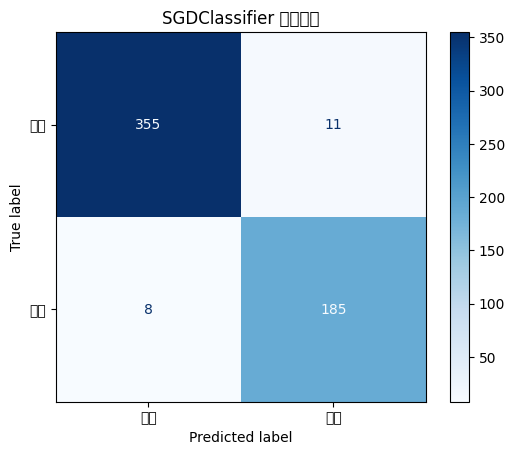

In [5]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
decision_scores = cross_val_predict(sgd_pipeline, X_train, y_train, cv=cv, method="decision_function")
cv_predictions = (decision_scores >= 0).astype(int)
cm = confusion_matrix(y_train, cv_predictions)
print(cm)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["良性", "恶性"]).plot(cmap="Blues")
plt.title("SGDClassifier 混淆矩阵")
plt.show()


## 6. Precision、Recall 和 F1

**这一步在做什么：** 6. Precision、Recall 和 F1。  
**为什么要做：** Accuracy 不能区分误报和漏诊；筛查通常优先 recall，F1 用于兼顾 precision 与 recall。  
**如何纳入 Pipeline：** 指标基于完整 Pipeline 的交叉验证预测。


In [6]:
from sklearn.metrics import precision_score, recall_score, f1_score
precision = precision_score(y_train, cv_predictions)
recall = recall_score(y_train, cv_predictions)
f1 = f1_score(y_train, cv_predictions)
display(pd.DataFrame({"metric": ["precision", "recall", "F1"], "value": [precision, recall, f1]}))
print("医学筛查通常优先 recall，因为漏掉恶性病例代价较高。")


,metric,value
0,precision,0.943878
1,recall,0.958549
2,F1,0.951157


医学筛查通常优先 recall，因为漏掉恶性病例代价较高。


## 7. Precision 和 Recall 随阈值变化

**这一步在做什么：** 7. Precision 和 Recall 随阈值变化。  
**为什么要做：** 默认阈值不一定适合医学筛查；提高阈值通常提高 precision，但降低 recall。  
**如何纳入 Pipeline：** 阈值只作用于完整 Pipeline 的 decision_function 输出，不改变预处理。


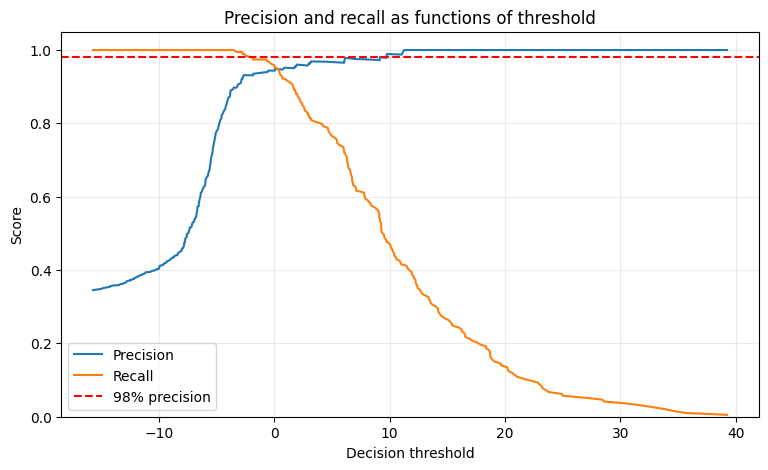

In [7]:
from sklearn.metrics import precision_recall_curve
precisions, recalls, thresholds = precision_recall_curve(y_train, decision_scores)
plt.figure(figsize=(9, 5))
plt.plot(thresholds, precisions[:-1], label="Precision")
plt.plot(thresholds, recalls[:-1], label="Recall")
plt.axhline(.98, color="red", linestyle="--", label="98% precision")
plt.xlabel("Decision threshold")
plt.ylabel("Score")
plt.title("Precision and recall as functions of threshold")
plt.ylim(0, 1.05)
plt.grid(alpha=.25)
plt.legend()
plt.show()


## 8. Precision 达到 98% 的阈值

**这一步在做什么：** 8. Precision 达到 98% 的阈值。  
**为什么要做：** 寻找 precision 至少为 98% 的最小决策阈值，给出可执行的高精确率工作点。  
**如何纳入 Pipeline：** 部署时先用同一 Pipeline 计算 decision_function，再应用该阈值。


In [8]:
target_precision = .98
valid = np.where(precisions[:-1] >= target_precision)[0]
if len(valid) == 0:
    print("当前交叉验证结果没有达到 98% precision 的阈值。")
else:
    i = valid[0]
    print(f"阈值：{thresholds[i]:.4f}")
    print(f"precision：{precisions[i]:.3f}，recall：{recalls[i]:.3f}")


阈值：9.1511
precision：0.981，recall：0.539


## 9. ROC 曲线和 ROC-AUC

**这一步在做什么：** 9. ROC 曲线和 ROC-AUC。  
**为什么要做：** ROC-AUC 衡量所有阈值下区分恶性和良性的能力，不依赖单一阈值。  
**如何纳入 Pipeline：** 分数来自完整 sgd_pipeline 的 decision_function。


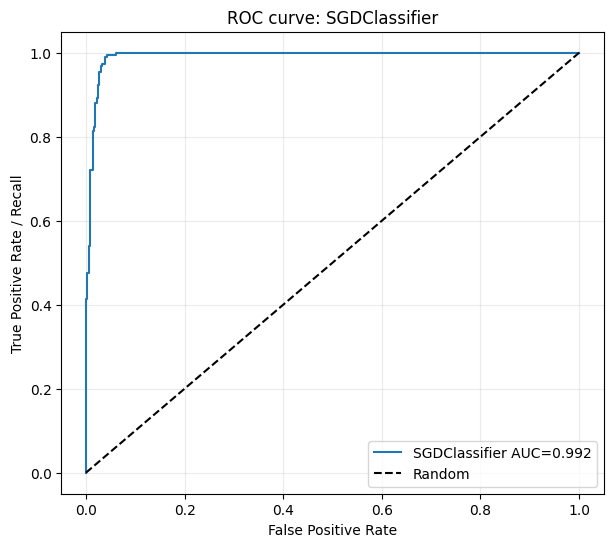

SGDClassifier ROC-AUC：0.992


In [9]:
from sklearn.metrics import roc_curve, roc_auc_score
fpr, tpr, _ = roc_curve(y_train, decision_scores)
sgd_auc = roc_auc_score(y_train, decision_scores)
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"SGDClassifier AUC={sgd_auc:.3f}")
plt.plot([0, 1], [0, 1], "k--", label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate / Recall")
plt.title("ROC curve: SGDClassifier")
plt.grid(alpha=.25)
plt.legend()
plt.show()
print(f"SGDClassifier ROC-AUC：{sgd_auc:.3f}")


## 10. 第二个分类器与 ROC-AUC 比较

**这一步在做什么：** 10. 第二个分类器与 ROC-AUC 比较。  
**为什么要做：** RandomForestClassifier 能表达非线性关系；比较 AUC 后还要结合 recall、precision 和医学代价。  
**如何纳入 Pipeline：** 随机森林也使用 SimpleImputer → StandardScaler → RandomForestClassifier 完整 Pipeline。


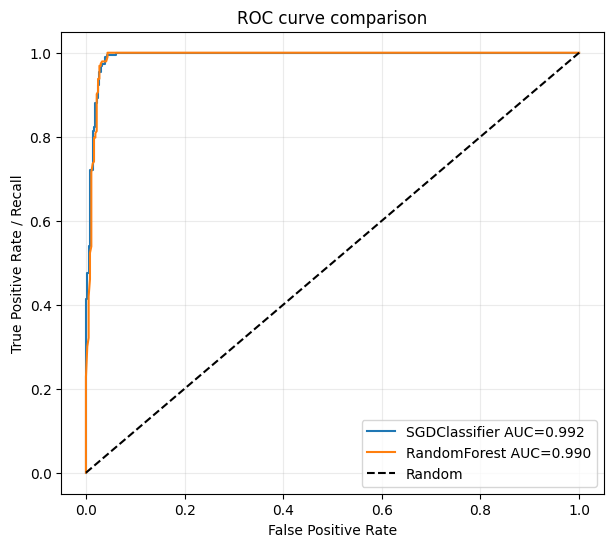

,classifier,ROC_AUC
0,SGDClassifier,0.99186
1,RandomForestClassifier,0.98997


In [10]:
from sklearn.ensemble import RandomForestClassifier
forest_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced", n_jobs=-1)),
])
forest_scores = cross_val_predict(forest_pipeline, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
forest_fpr, forest_tpr, _ = roc_curve(y_train, forest_scores)
forest_auc = roc_auc_score(y_train, forest_scores)
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"SGDClassifier AUC={sgd_auc:.3f}")
plt.plot(forest_fpr, forest_tpr, label=f"RandomForest AUC={forest_auc:.3f}")
plt.plot([0, 1], [0, 1], "k--", label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate / Recall")
plt.title("ROC curve comparison")
plt.grid(alpha=.25)
plt.legend()
plt.show()
display(pd.DataFrame({"classifier": ["SGDClassifier", "RandomForestClassifier"], "ROC_AUC": [sgd_auc, forest_auc]}))


# 总结

本数据集包含 699 条样本和 9 个细胞核形态特征，标签 2 为良性、4 为恶性，bare_nuclei 的问号表示缺失。设计目标是辅助筛查恶性肿瘤，因此优先关注 recall。Pipeline 将中位数填补、标准化和分类器锁在一起，避免交叉验证中的数据泄漏。阈值曲线展示 precision 与 recall 的权衡，98% precision 的阈值需要同时报告对应 recall；ROC-AUC 比较模型在所有阈值下的排序能力。第二个分类器即使 AUC 更高，也应结合高 recall 工作点、误报和漏诊成本做最终选择。
